Для решения задачи классификации вернемся к первой промежуточной аттестации, т.к. выбрана я тема отлично подходит для задачи классифкакации.
В качсестве бинарной переменной будем использовать показатель предаварийного состояния оборудования failure_next_24h.

Целевая переменная Y:
failure_next_24h (бинарный признак: 1 — до аварийного останова станка осталось менее 24 часов (предаварийный режим), 0 — оборудование работает стабильно).

Объясняющие переменные (X):
1. rpm_std (стандартное отклонение скорости вращения) — резкий рост разброса оборотов указывает на появление люфта, биения или износа подшипников автоматики.
2. temp_std (стандартное отклонение температуры) — нестабильность температурного режима и микроскачки трения в узлах являются прямым предвестником деградации деталей.
3. start_count (количество запусков станка за интервал) — пусковые режимы создают экстремальные электромеханические нагрузки, и высокая частота циклов «старт-стоп» лавинообразно ускоряет поломку.
4. press_trend (динамический тренд давления) — нестабильность или падение давления в системе сигнализируют о микроутечках смазки, износе сальников или сбоях клапанов.

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    classification_report, 
    confusion_matrix, 
    precision_recall_curve, 
    roc_curve, 
    auc, 
    f1_score, 
    precision_score, 
    recall_score
)
from imblearn.under_sampling import RandomUnderSampler

 

In [ ]:
# загрузим данные, определим таргет и фичи

df = pd.read_csv("../v_machine_features_predictive.csv", parse_dates=['snapshot_time'])

# сортирую по времени
df = df.sort_values('snapshot_time').reset_index(drop=True)

# задаю таргет (т.к. ссбытие отказа либо произошло ли бо нет, таргет банарный)
target = 'failure_next_24h'
features = ['rpm_std', 'temp_std', 'start_count', 'press_trend', 'power_avg']

# подготовим датафрейм. Т.к. в датафрейме много пропусков заполним их последними известными значениями и медианой
df_clf = df[['machine_id', target] + features].copy()

df_clf[features] = df_clf.groupby('machine_id')[features].ffill()
df_clf[features] = df_clf.groupby('machine_id')[features].bfill()

for col in features:
    df_clf[col] = df_clf[col].fillna(df_clf[col].median())


df_clf = df_clf[[target] + features]

# 4. Проверяем финальный результат
print(f"Общий размер датасета после корректного заполнения: {df_clf.shape[0]} строк")
print("\nТочный дисбаланс классов для обучения модели:")
print(df_clf[target].value_counts())
print("\nДоля предаварийных состояний (класс 1):")
print(f"{df_clf[target].mean() * 100:.2f}%")

Общий размер датасета после корректного заполнения: 395520 строк

Точный дисбаланс классов для обучения модели:
failure_next_24h
0    391996
1      3524
Name: count, dtype: int64

Доля предаварийных состояний (класс 1):
0.89%


In [41]:
df_clf.info()

<class 'pandas.DataFrame'>
RangeIndex: 395520 entries, 0 to 395519
Data columns (total 6 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   failure_next_24h  395520 non-null  int64  
 1   rpm_std           395520 non-null  float64
 2   temp_std          395520 non-null  float64
 3   start_count       395520 non-null  int64  
 4   press_trend       395520 non-null  float64
 5   power_avg         395520 non-null  float64
dtypes: float64(4), int64(2)
memory usage: 18.1 MB


Проверка статистической значимости признаков (U-тест Манна-Уитни)
rpm_std: p-value = 0.00001 (статистически значимо)
temp_std: p-value = 0.77800 (не значимо)
start_count: p-value = 0.00000 (статистически значимо)
press_trend: p-value = 0.75585 (не значимо)
power_avg: p-value = 0.17772 (не значимо)


/tmp/ipykernel_1054/2704919420.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=target, y=col, data=df_clf, ax=axes[i], palette='muted')
/tmp/ipykernel_1054/2704919420.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=target, y=col, data=df_clf, ax=axes[i], palette='muted')
/tmp/ipykernel_1054/2704919420.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=target, y=col, data=df_clf, ax=axes[i], palette='muted')


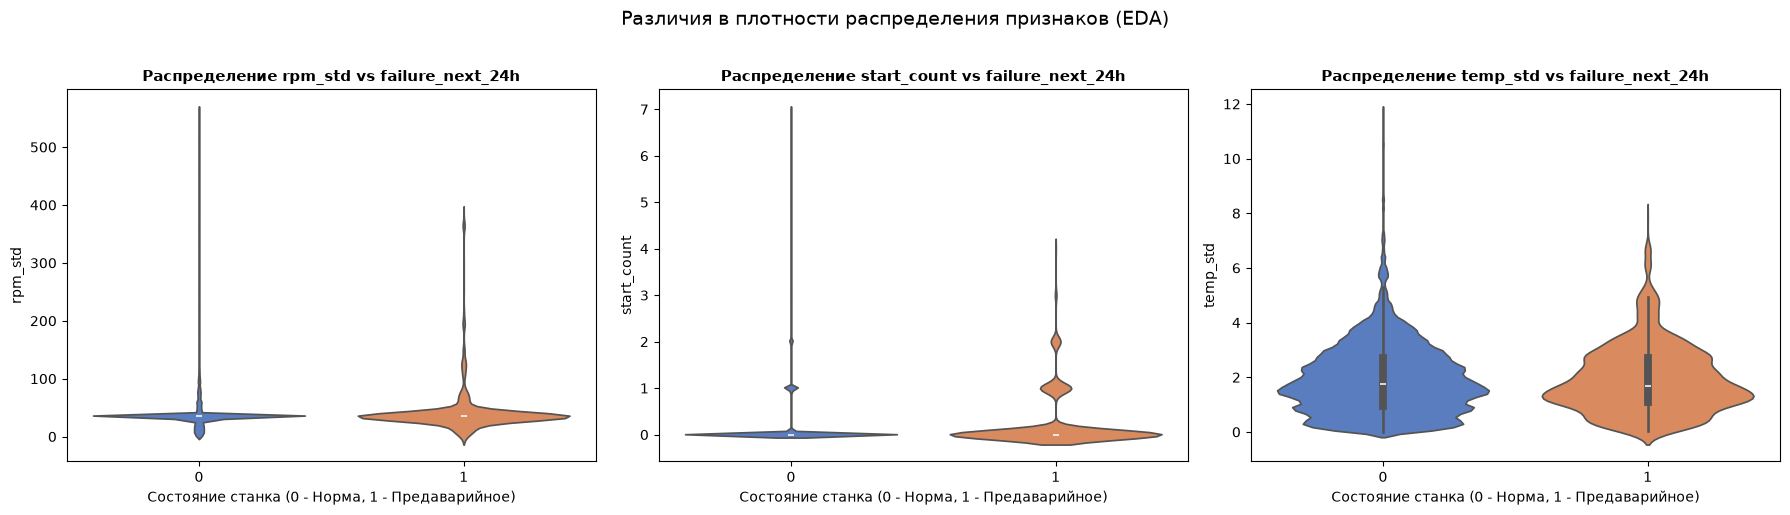

In [42]:
# Теперь проведем разведочный анализ и проверим статистическую значимость
print("Проверка статистической значимости признаков (U-тест Манна-Уитни)")
for col in features:
    stat, p = mannwhitneyu(
        df_clf[df_clf[target] == 0][col], 
        df_clf[df_clf[target] == 1][col],
        nan_policy='omit'
    )
    status = 'статистически значимо' if p < 0.05 else 'не значимо'
    print(f"{col}: p-value = {p:.5f} ({status})")

# Построим графики violinplot для визуализации 
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
top_features = ['rpm_std', 'start_count', 'temp_std']

for i, col in enumerate(top_features):
    sns.violinplot(x=target, y=col, data=df_clf, ax=axes[i], palette='muted')
    axes[i].set_title(f'Распределение {col} vs {target}', fontsize=11, fontweight='bold')
    axes[i].set_xlabel('Состояние станка (0 - Норма, 1 - Предаварийное)')
    axes[i].set_ylabel(col)

plt.suptitle('Различия в плотности распределения признаков (EDA)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()




In [43]:
# Проведем разделение и балансировку выборки в соответствии с рекомендациями по 1 промежуточной аттестации. 

# Разделяем на матрицу признаков X и целевую переменную y
X = df_clf[features]
y = df_clf[target]

# Разделяем на train и test хронологически (без перемешивания), чтобы избежать утечки данных
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, shuffle=False)

print("--- Состояние выборок до балансировки ---")
print(f"Обучающая (Train): {y_train.value_counts().to_dict()}")
print(f"Контрольная (Test): {y_test.value_counts().to_dict()}\n")

# Применяем Undersampling только к Train выборке
# Подтягиваем долю предаварийных состояний до 10% от нормы до пропорции 1:10
rus = RandomUnderSampler(sampling_strategy=0.1, random_state=42)
X_train_res, y_train_res = rus.fit_resample(X_train, y_train)

print("--- Состояние выборок после балансировки ---")
print(f"Сбалансированная обучающая (Train): {y_train_res.value_counts().to_dict()}")
print(f"Честная тестовая (Test) — НЕ балансируется: {y_test.value_counts().to_dict()}\n")

# Проведем масштабирование признаков для алгоритма KNN!
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_res)
X_test_scaled = scaler.transform(X_test)



--- Состояние выборок до балансировки ---
Обучающая (Train): {0: 313534, 1: 2882}
Контрольная (Test): {0: 78462, 1: 642}

--- Состояние выборок после балансировки ---
Сбалансированная обучающая (Train): {0: 28820, 1: 2882}
Честная тестовая (Test) — НЕ балансируется: {0: 78462, 1: 642}



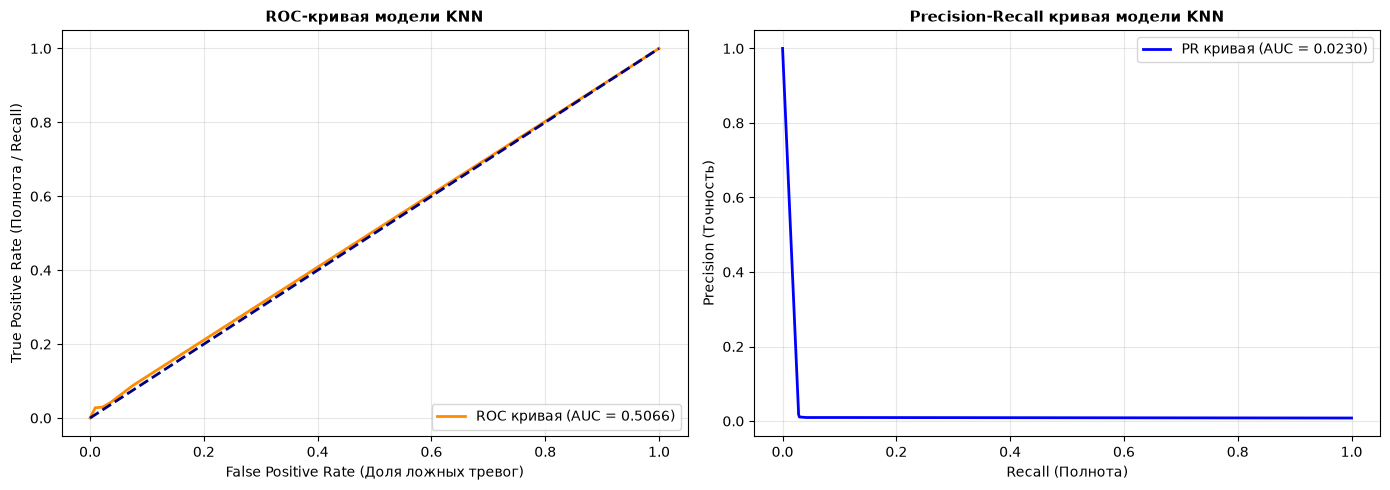

In [45]:
# Провелдем обучение модели KNN и построение кривых ROC и Precision-Recall


# Обучаем классификатор KNN (задаем 5 соседей и задействуем все ядра процессора для скорости)

knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)
knn.fit(X_train_scaled, y_train_res)

# Получаем вероятности предаварийного состояния (класс 1) на тестовой выборке
y_scores = knn.predict_proba(X_test_scaled)[:, 1]

# Графики ROC и Precision-Recall
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1. Левый график: ROC-кривая (обращаемся через ax[0])
fpr, tpr, _ = roc_curve(y_test, y_scores)
roc_auc = auc(fpr, tpr)
ax[0].plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC кривая (AUC = {roc_auc:.4f})')
ax[0].plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
ax[0].set_xlabel('False Positive Rate (Доля ложных тревог)')
ax[0].set_ylabel('True Positive Rate (Полнота / Recall)')
ax[0].set_title('ROC-кривая модели KNN', fontsize=11, fontweight='bold')
ax[0].legend(loc="lower right")
ax[0].grid(True, alpha=0.3)

# 2. Правый график: Precision-Recall кривая (обращаемся через ax[1])
precision, recall, _ = precision_recall_curve(y_test, y_scores)
pr_auc = auc(recall, precision)
ax[1].plot(recall, precision, color='blue', lw=2, label=f'PR кривая (AUC = {pr_auc:.4f})')
ax[1].set_xlabel('Recall (Полнота)')
ax[1].set_ylabel('Precision (Точность)')
ax[1].set_title('Precision-Recall кривая модели KNN', fontsize=11, fontweight='bold')
ax[1].legend(loc="upper right")
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Проведенный эксперимент показал, что классический алгоритм KNN не применим для задач предиктивного обслуживания на имеющемся наборе данных. Из-за временной зависимости признаков и высокой разреженности IoT-телеметрии геометрическая близость объектов в пространстве признаков не отражает реального физического износа, что требует перехода к моделям на основе деревьев решений или нейросетей.

--- ОТЧЕТ ПО МЕТРИКАМ КАЧЕСТВА (Порог = 0.2) ---
              precision    recall  f1-score   support

   Норма (0)       0.99      0.93      0.96     78462
   Отказ (1)       0.01      0.09      0.02       642

    accuracy                           0.92     79104
   macro avg       0.50      0.51      0.49     79104
weighted avg       0.98      0.92      0.95     79104



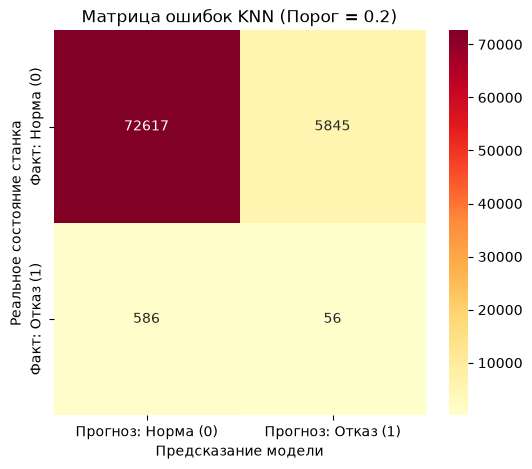

In [ ]:
# выбор порога предсказания. 
# для текущегонабора данных и задачи предиктивного обсуживания предлагаю использовать порог 0.2 для 5 ближайших соседей. 
# это будет означать что если хотябы одна из 5 точек покажет риск отказа то ИИ его зафиксирует
# Выбираем порог 0.2
chosen_threshold = 0.2
y_pred_final = (y_scores >= chosen_threshold).astype(int)

print(f"ОТЧЕТ ПО МЕТРИКАМ КАЧЕСТВА (Порог = {chosen_threshold})")
# zero_division=0 защитит от ошибок, если precision в каком-то классе упадет в 0
print(classification_report(y_test, y_pred_final, target_names=['Норма (0)', 'Отказ (1)'], zero_division=0))

# Строим матрицу ошибок
cm = confusion_matrix(y_test, y_pred_final)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='YlOrRd', 
            xticklabels=['Прогноз: Норма (0)', 'Прогноз: Отказ (1)'], 
            yticklabels=['Факт: Норма (0)', 'Факт: Отказ (1)'])
plt.ylabel('Реальное состояние станка')
plt.xlabel('Предсказание модели')
plt.title(f'Матрица ошибок KNN (Порог = {chosen_threshold})')
plt.show()


Даже порог предсказания 0.2 показывает низкуэ точность предасказания модели. Метрика Recall для класса поломок составила всего 9%, а Precision — 1%.

Вывод:
* Оценка применимости алгоритма:
     Построенная модель на базе алгоритма K-Ближайших Соседей (KNN) показала неудовлетворительное качество f1-score = 0.02 для целевого класса.
Для успешной реализации ИИ-платформы алгоритм KNN не подходит. Дальнейшие исследования применимости моделей необходитмо  проводить на базе ансамблей деревьев решений или нейросетей для временных рядов.